# 03 · Twist: tasas, COP y liquidez de CL_02

Llegan tres noticias nuevas con fecha efectiva 2026-08-17, el lunes siguiente al último dato (2026-08-14). No hay precios posteriores, así que esto es un **análisis de escenarios**: se usa la historia para ver qué tan fuera de rango está cada shock y qué activos son más vulnerables.

Usa las tablas limpias de `01_calidad_y_limpieza.ipynb`.

Contenido:
1. Las noticias del twist
2. TW_01 · Subida de 65 pb en la tasa 10Y
3. TW_03 · Depreciación de 8% del COP
4. TW_02 · CL_02 necesita el 30% en 6 meses
5. Escenario combinado para CL_02
6. Conclusiones por cliente

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.figsize': (11, 4.5), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .3})

RAW = Path('../dataset_start')
CLEAN = Path('../data_clean')
prices = pd.read_csv(CLEAN / 'prices_daily.csv', parse_dates=['date'])
macro = pd.read_csv(CLEAN / 'macro.csv', parse_dates=['date']).set_index('date')
ref = pd.read_csv(CLEAN / 'asset_reference.csv').set_index('asset_id')
clients = pd.read_csv(CLEAN / 'client_profiles.csv').set_index('client_id')

close = prices.pivot(index='date', columns='asset_id', values='close')
ret = close.pct_change()
ASSETS = list(close.columns)
SHORT = {a: a[3:] for a in ASSETS}

def max_drawdown(s):
    return (s / s.cummax() - 1).min()

## 1. Las noticias del twist

In [2]:
twist = pd.read_csv(RAW / 'dataset_twist.csv', encoding='utf-8-sig', parse_dates=['effective_date'])
print('Nulos:', int(twist.isna().sum().sum()), '| Duplicados:', int(twist.duplicated().sum()))
print('Último dato de precios:', close.index.max().date(), '| Fecha efectiva del twist:', twist.effective_date.max().date())
twist

Nulos: 0 | Duplicados: 0
Último dato de precios: 2026-08-14 | Fecha efectiva del twist: 2026-08-17


,release_id,effective_date,type,field,new_information,required_action
0,TW_01,2026-08-17,Macro,us_10y_yield,La tasa de 10 años sube 65 pb en una semana po...,Decidir si cambia su lectura de sensibilidad a...
1,TW_02,2026-08-17,Client,CL_02_liquidity,CL_02 necesitará disponer de 30% del portafoli...,Revisar si la recomendación sigue siendo adecu...
2,TW_03,2026-08-17,FX,USD_COP,El COP se deprecia 8% frente al USD en pocos d...,Evaluar impacto para un cliente cuya moneda ba...


El archivo viene limpio. El twist empieza justo después del último precio disponible, así que su efecto no se puede observar: hay que estimarlo.

## 2. TW_01 · La tasa 10Y sube 65 pb en una semana
Primero: ¿qué tan grande es 65 pb comparado con lo que se vio en la muestra?

In [3]:
y10 = macro.us_10y_yield
dy_bp = y10.diff() * 100
wk_bp = y10.resample('W-FRI').last().diff() * 100
shock_bp = 65

scale = pd.Series({
    'rango de la tasa en la muestra (%)': f'{y10.min():.2f} – {y10.max():.2f}',
    'mayor alza semanal en la muestra (pb)': round(wk_bp.max(), 1),
    'desviación estándar semanal (pb)': round(wk_bp.std(), 2),
    'shock del twist (pb)': shock_bp,
    'shock en desviaciones estándar semanales': round(shock_bp / wk_bp.std(), 1),
}, name='valor')
scale.to_frame()

,valor
rango de la tasa en la muestra (%),4.10 – 4.40
mayor alza semanal en la muestra (pb),2.1
desviación estándar semanal (pb),1.08
shock del twist (pb),65
shock en desviaciones estándar semanales,60.4


Text(0.5, 0, '')

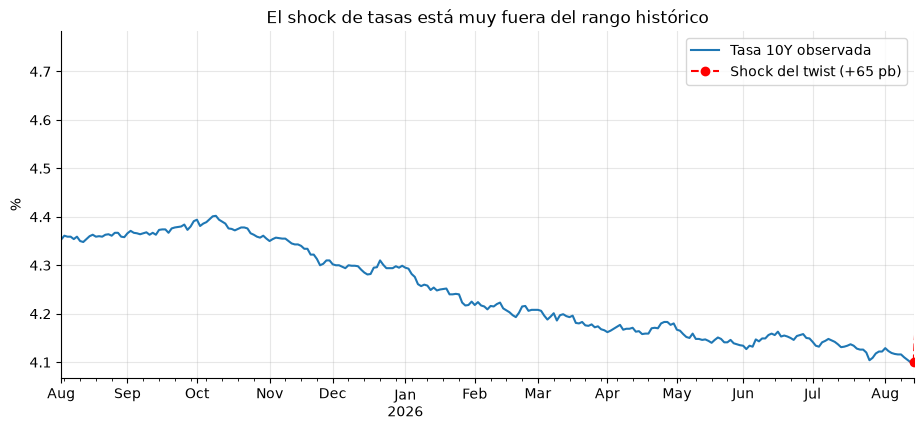

In [4]:
fig, ax = plt.subplots()
y10.plot(ax=ax, label='Tasa 10Y observada')
ax.plot([y10.index[-1], twist.effective_date.max() + pd.Timedelta(days=4)],
        [y10.iloc[-1], y10.iloc[-1] + shock_bp / 100], 'r--', marker='o', label='Shock del twist (+65 pb)')
ax.set_title('El shock de tasas está muy fuera del rango histórico'); ax.set_ylabel('%'); ax.legend(); ax.set_xlabel('')

### ¿La historia permite estimar la sensibilidad a tasas?
Se mide la correlación y la beta de cada activo frente al cambio diario y semanal de la tasa, controlando por el factor de mercado.

In [5]:
X = pd.concat([ret, dy_bp.rename('dy_bp'), macro.market_factor], axis=1).dropna()
wret = close.resample('W-FRI').last().pct_change()
W = pd.concat([wret, wk_bp.rename('dy_bp')], axis=1).dropna()

rows = {}
for a in ASSETS:
    A = np.column_stack([X.dy_bp, X.market_factor, np.ones(len(X))])
    coef, *_ = np.linalg.lstsq(A, X[a], rcond=None)
    resid = X[a] - A @ coef
    se = np.sqrt(resid.var(ddof=3) * np.linalg.inv(A.T @ A)[0, 0])
    rows[a] = {
        'corr_diaria': X[a].corr(X.dy_bp),
        'corr_semanal': W[a].corr(W.dy_bp),
        'beta_%_por_pb': coef[0] * 100,
        't_stat': coef[0] / se,
        'impacto_lineal_65pb_%': coef[0] * shock_bp * 100,
    }
sens = ref[['name', 'sector']].join(pd.DataFrame(rows).T.round(3))
sens

,name,sector,corr_diaria,corr_semanal,beta_%_por_pb,t_stat,impacto_lineal_65pb_%
asset_id,,,,,,,
VF_A01,Andes Consumer,Consumer Staples,0.080,0.165,0.135,1.048,8.799
VF_A02,Pacifica Digital,Technology,0.023,0.080,-0.026,-0.095,-1.685
VF_A03,Cordillera Energy,Energy,0.082,0.205,0.209,0.978,13.596
VF_A04,Lima Financial,Financials,0.029,0.042,-0.011,-0.065,-0.698
VF_A05,Aurora Health,Health Care,0.113,0.230,0.220,1.525,14.295
VF_A06,Norte Industrials,Industrials,-0.043,-0.024,-0.273,-1.375,-17.749
VF_A07,Sierra Materials,Materials,0.066,-0.058,0.175,0.731,11.345
VF_A08,Atlas Utilities,Utilities,0.107,0.103,0.149,1.512,9.696


Las correlaciones son casi cero y ningún `t_stat` pasa de ±2: **la muestra no tiene información sobre cómo reaccionan estos activos a tasas**. Además los signos no siguen ninguna lógica por sector (según la regresión, A08 "subiría" con la tasa y A04 "bajaría"), lo que confirma que es ruido. La columna `impacto_lineal_65pb_%` no debe usarse.

Como la historia no alcanza, el impacto se evalúa por sector, que es como lo haría un analista. La escala va de −2 (muy perjudicado) a +1 (beneficiado).

In [6]:
rate_view = pd.DataFrame({
    'VF_A01': (-1, 'Consumo defensivo: cae poco, pero cae si el mercado se ajusta'),
    'VF_A02': (-2, 'Tecnología de crecimiento: valor muy sensible a la tasa de descuento; ya cayó con el repricing del 21 de julio'),
    'VF_A03': (0, 'Energía: suele resistir cuando la tasa sube por inflación'),
    'VF_A04': (1, 'Financiero: más margen de interés con tasas altas'),
    'VF_A05': (-1, 'Salud: defensivo, sensibilidad moderada'),
    'VF_A06': (-1, 'Industrial: cíclico y con la mayor deuda relativa del grupo'),
    'VF_A07': (0, 'Materiales: ligado a inflación, pero con demanda externa débil (evento 8 de junio)'),
    'VF_A08': (-2, 'Utilities: se comporta como un bono; pierde atractivo frente a la renta fija'),
}, index=['sensibilidad_tasas', 'razón']).T
rate_view['sensibilidad_tasas'] = rate_view.sensibilidad_tasas.astype(int)
ref[['name', 'sector']].join(rate_view).sort_values('sensibilidad_tasas')

,name,sector,sensibilidad_tasas,razón
asset_id,,,,
VF_A02,Pacifica Digital,Technology,-2,Tecnología de crecimiento: valor muy sensible ...
VF_A08,Atlas Utilities,Utilities,-2,Utilities: se comporta como un bono; pierde at...
VF_A01,Andes Consumer,Consumer Staples,-1,"Consumo defensivo: cae poco, pero cae si el me..."
VF_A05,Aurora Health,Health Care,-1,"Salud: defensivo, sensibilidad moderada"
VF_A06,Norte Industrials,Industrials,-1,Industrial: cíclico y con la mayor deuda relat...
VF_A03,Cordillera Energy,Energy,0,Energía: suele resistir cuando la tasa sube po...
VF_A07,Sierra Materials,Materials,0,"Materiales: ligado a inflación, pero con deman..."
VF_A04,Lima Financial,Financials,1,Financiero: más margen de interés con tasas altas


**Ojo:** A08, el activo más estable de la muestra y candidato natural para el cliente conservador, es de los más expuestos a este shock.

## 3. TW_03 · El COP se deprecia 8%
Todos los activos cotizan en USD. Para un cliente que mide en COP:

`retorno en COP = (1 + retorno en USD) × (1 + variación del USD/COP) − 1`

In [7]:
cop = macro.usd_cop
dcop = cop.pct_change()
cop5 = cop.pct_change(5)
fx_shock = 0.08

fx_scale = pd.Series({
    'mayor depreciación del COP en 5 días (%)': round(cop5.max() * 100, 2),
    'vol anual del USD/COP (%)': round(dcop.std() * np.sqrt(252) * 100, 2),
    'shock del twist (%)': fx_shock * 100,
    'shock en desviaciones estándar de 5 días': round(fx_shock / (dcop.std() * np.sqrt(5)), 1),
}, name='valor')
display(fx_scale.to_frame())
print('Correlación de cada activo con el USD/COP diario:')
ret.corrwith(dcop).round(2).to_frame('corr_con_usdcop').T

,valor
mayor depreciación del COP en 5 días (%),2.19
vol anual del USD/COP (%),5.54
shock del twist (%),8.00
shock en desviaciones estándar de 5 días,10.20


Correlación de cada activo con el USD/COP diario:


asset_id,VF_A01,VF_A02,VF_A03,VF_A04,VF_A05,VF_A06,VF_A07,VF_A08
corr_con_usdcop,-0.1,-0.09,0.03,0.08,0.05,-0.02,0.06,0.01


El shock también está muy fuera de rango. La correlación casi nula significa que nada en el portafolio compensa o amplifica el movimiento: el efecto es puramente de conversión.

Text(0.5, 0, '')

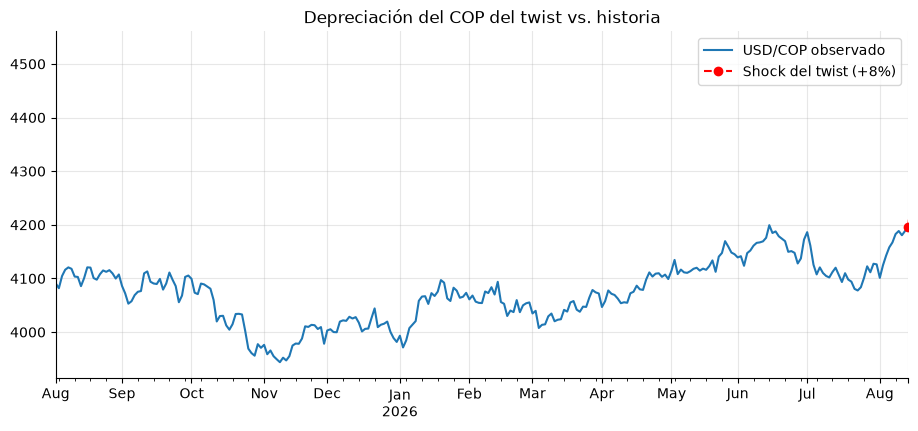

In [8]:
fig, ax = plt.subplots()
cop.plot(ax=ax, label='USD/COP observado')
ax.plot([cop.index[-1], twist.effective_date.max() + pd.Timedelta(days=4)],
        [cop.iloc[-1], cop.iloc[-1] * (1 + fx_shock)], 'r--', marker='o', label='Shock del twist (+8%)')
ax.set_title('Depreciación del COP del twist vs. historia'); ax.legend(); ax.set_xlabel('')

In [9]:
usd_ret = (close.iloc[-1] / close.iloc[0] - 1)
cop_hist = cop.iloc[-1] / cop.iloc[0] - 1
fx_tab = pd.DataFrame({
    'retorno_USD_%': usd_ret * 100,
    'retorno_COP_sin_twist_%': ((1 + usd_ret) * (1 + cop_hist) - 1) * 100,
    'retorno_COP_con_twist_%': ((1 + usd_ret) * (1 + cop_hist) * (1 + fx_shock) - 1) * 100,
}).round(1)
fx_tab

,retorno_USD_%,retorno_COP_sin_twist_%,retorno_COP_con_twist_%
asset_id,,,
VF_A01,-10.0,-7.7,-0.3
VF_A02,-13.8,-11.6,-4.5
VF_A03,-26.5,-24.6,-18.6
VF_A04,20.5,23.6,33.4
VF_A05,31.9,35.3,46.1
VF_A06,-22.4,-20.5,-14.1
VF_A07,-26.7,-24.8,-18.8
VF_A08,-14.2,-12.0,-4.9


## 4. TW_02 · CL_02 necesita el 30% del portafolio en 6 meses
Todos los activos negocian volúmenes parecidos, así que vender no es el problema. El problema es que ese 30% pasa a tener un **horizonte de 6 meses** y no puede aguantar una caída justo antes de retirarse.

In [10]:
print('Volumen promedio diario (millones de acciones):')
display((prices.groupby('asset_id').volume.mean() / 1e6).round(2).to_frame('vol_M').T)
print('Perfil original de CL_02:')
clients.loc['CL_02']

Volumen promedio diario (millones de acciones):


asset_id,VF_A01,VF_A02,VF_A03,VF_A04,VF_A05,VF_A06,VF_A07,VF_A08
vol_M,1.86,1.7,1.87,1.77,1.82,1.76,1.87,1.87


Perfil original de CL_02:


profile_name                                       Patrimonio Estable
base_currency                                                     COP
horizon_months                                                     36
risk_tolerance                                             Media-Baja
max_drawdown_tolerance_pct                                         10
liquidity_need                                                  Media
priority                          Preservación + crecimiento moderado
constraint                    Máx. 25% en activos de alta volatilidad
Name: CL_02, dtype: object

In [11]:
H = 126  # ~6 meses hábiles
r6 = close.pct_change(H)
six = pd.DataFrame({
    'peor_6m_%': r6.min() * 100,
    'mediana_6m_%': r6.median() * 100,
    'ventanas_con_pérdida_%': (r6 < 0).mean() * 100,
    'vol_anual_%': ret.std() * np.sqrt(252) * 100,
    'caída_máx_%': close.apply(max_drawdown) * 100,
}).round(1)
ref[['name']].join(six).sort_values('peor_6m_%', ascending=False)

,name,peor_6m_%,mediana_6m_%,ventanas_con_pérdida_%,vol_anual_%,caída_máx_%
asset_id,,,,,,
VF_A04,Lima Financial,1.6,12.8,0.0,28.2,-17.4
VF_A05,Aurora Health,-3.1,6.7,4.4,24.0,-13.5
VF_A01,Andes Consumer,-15.8,-4.0,50.6,20.1,-27.4
VF_A08,Atlas Utilities,-17.1,0.3,26.2,15.4,-22.2
VF_A07,Sierra Materials,-24.9,-8.9,47.2,38.3,-36.2
VF_A06,Norte Industrials,-30.0,-13.8,48.3,33.5,-37.1
VF_A03,Cordillera Energy,-32.6,-20.6,52.0,34.9,-42.5
VF_A02,Pacifica Digital,-46.5,-27.7,45.4,45.2,-55.4


Text(0.5, 0, '')

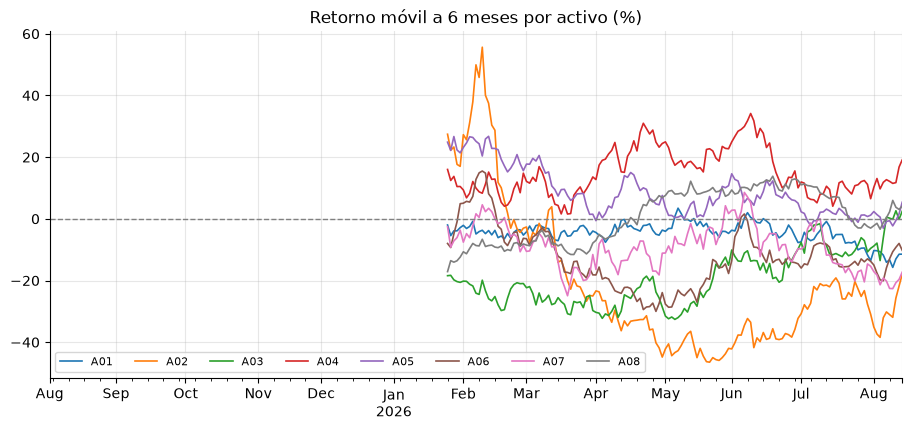

In [12]:
fig, ax = plt.subplots()
(r6 * 100).rename(columns=SHORT).plot(ax=ax, lw=1.2)
ax.axhline(0, color='grey', ls='--', lw=1)
ax.set_title('Retorno móvil a 6 meses por activo (%)'); ax.legend(ncol=8, fontsize=8); ax.set_xlabel('')

Solo hay 271 días de datos, así que las ventanas de 6 meses se solapan mucho: es evidencia débil. A04 y A05 se ven muy bien porque fueron los ganadores de este año, no necesariamente porque sean seguros. A08, pese a ser el menos volátil, tuvo peores caídas a 6 meses que A04 y A05.

## 5. Escenario combinado para CL_02
Se comparan portafolios candidatos. Para cada uno:
- métricas históricas en USD (volatilidad, caída máxima, peor resultado a 6 meses),
- **impacto estimado del twist en COP**: el +8% del COP más un shock de tasas por sector.

El shock de tasas por sector es un **supuesto explícito**: cada punto de la escala de sensibilidad equivale a 3% de precio (−2 → −6%, +1 → +3%). Se puede cambiar abajo.

In [13]:
PCT_PER_POINT = 0.03
rate_shock = rate_view.sensibilidad_tasas * PCT_PER_POINT

portfolios = {
    'Igual peso': {a: 1 / 8 for a in ASSETS},
    'Defensivo previo (A08+A01+A05)': {'VF_A08': 1 / 3, 'VF_A01': 1 / 3, 'VF_A05': 1 / 3},
    'Ajustado al twist': {'VF_A04': .30, 'VF_A05': .30, 'VF_A01': .25, 'VF_A03': .15},
}

def evaluate(w):
    w = pd.Series(w)
    pr = (ret[w.index] * w).sum(axis=1)
    curve = (1 + pr).cumprod()
    rate_hit = (w * rate_shock[w.index]).sum()
    return {
        'vol_anual_%': pr.std() * np.sqrt(252) * 100,
        'caída_máx_%': max_drawdown(curve) * 100,
        'peor_6m_%': curve.pct_change(H).min() * 100,
        'shock_tasas_%': rate_hit * 100,
        'twist_en_COP_%': ((1 + rate_hit) * (1 + fx_shock) - 1) * 100,
        'peso_alta_vol_%': w[six.loc[w.index, 'vol_anual_%'] > 30].sum() * 100,
        'países': ref.loc[w.index, 'country'].nunique(),
    }

comp = pd.DataFrame({k: evaluate(v) for k, v in portfolios.items()}).T.round(1)
comp['cumple_caída_10%'] = comp['caída_máx_%'].abs() <= clients.loc['CL_02', 'max_drawdown_tolerance_pct']
comp['cumple_25%_alta_vol'] = comp['peso_alta_vol_%'] <= 25
comp

,vol_anual_%,caída_máx_%,peor_6m_%,shock_tasas_%,twist_en_COP_%,peso_alta_vol_%,países,cumple_caída_10%,cumple_25%_alta_vol
Igual peso,15.8,-19.3,-12.0,-2.2,5.6,50.0,5.0,False,False
Defensivo previo (A08+A01+A05),12.7,-11.8,-4.9,-4.0,3.7,0.0,2.0,False,True
Ajustado al twist,16.6,-11.6,-3.6,-0.8,7.2,15.0,3.0,False,True


"Alta volatilidad" se define aquí como volatilidad anual mayor a 30%, para medir la restricción de CL_02 (máx. 25% en activos de alta volatilidad).

El portafolio "Ajustado al twist" saca a A08 y A02 (los más expuestos a tasas), pone más peso en A04 y A05, y deja una parte pequeña en A03 como cobertura frente a inflación.

Qué muestra la comparación:
- El ajustado tiene la menor exposición al shock de tasas y el mejor peor resultado a 6 meses, pero **más volatilidad** que el defensivo previo, porque A04 y A03 son más volátiles que A08.
- **Ningún candidato cumple el límite de caída de 10%** de CL_02 con solo acciones. Es otro argumento para sacar el 30% de liquidez a un instrumento fuera del dataset.
- Las cifras de A04 y A05 se apoyan en que fueron los ganadores del año: hay riesgo de sobreajuste.

**Es un ejemplo para comparar, no una optimización**: los pesos se definen en la fase Find the signal.

Text(0.5, 0, '')

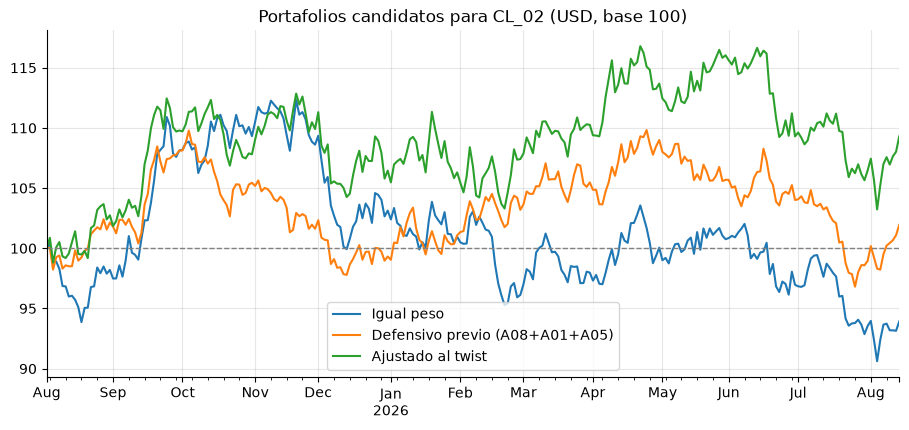

In [14]:
fig, ax = plt.subplots()
for k, w in portfolios.items():
    w = pd.Series(w)
    ((1 + (ret[w.index] * w).sum(axis=1)).cumprod() * 100).plot(ax=ax, label=k)
ax.axhline(100, color='grey', ls='--', lw=1)
ax.set_title('Portafolios candidatos para CL_02 (USD, base 100)'); ax.legend(); ax.set_xlabel('')

### El 30% de liquidez

In [15]:
w = pd.Series(portfolios['Ajustado al twist'])
liq = 0.30
value_cop_now = 1 + fx_shock
sens_fx = pd.DataFrame({
    'COP se recupera (%)': [0, -4, -8],
}).assign(
    valor_del_30_en_COP=lambda d: (liq * value_cop_now * (1 + d['COP se recupera (%)'] / 100) * 100).round(2),
)
sens_fx['vs_asegurar_hoy'] = (sens_fx.valor_del_30_en_COP - liq * value_cop_now * 100).round(2)
print('Valor en COP del 30% a retirar (base 100 = portafolio antes del twist), si no se cubre y solo se mueve el tipo de cambio:')
sens_fx

Valor en COP del 30% a retirar (base 100 = portafolio antes del twist), si no se cubre y solo se mueve el tipo de cambio:


,COP se recupera (%),valor_del_30_en_COP,vs_asegurar_hoy
0,0,32.40,0.00
1,-4,31.10,-1.30
2,-8,29.81,-2.59


Si el COP devuelve la depreciación antes del retiro, ese 30% pierde la ganancia cambiaria. Asegurarlo hoy en COP fija los 32.4 puntos.

## 6. Conclusiones por cliente

| Cliente | Impacto del twist | Ajuste recomendado |
|---|---|---|
| **CL_02 · Preservación (COP)** | Los tres cambios lo afectan. El +8% del COP sube el valor de su portafolio en pesos; el shock de tasas golpea a A08, que era su activo "estable"; y el 30% que necesita en 6 meses ya no puede estar en renta variable volátil. | Separar el portafolio: **70% a 36 meses** y **30% a 6 meses**. Asegurar en COP el 30% ahora para fijar la ganancia cambiaria (lo ideal es efectivo o renta fija en COP, que no están en el dataset: supuesto a declarar). En el resto, menos peso en A08 y A02 y más en A04 y A05, respetando el límite de 25% en alta volatilidad. |
| **CL_01 · Crecimiento (USD)** | Solo el shock de tasas. | Evitar o reducir A02. A04 gana atractivo con tasas altas. |
| **CL_03 · Regional (PEN)** | Solo el shock de tasas. El twist no informa sobre el PEN. | Mantener la diversificación; vigilar si la depreciación es regional (sería especulación con estos datos). |

**Limitaciones**
- Los dos shocks están a unas 10 desviaciones estándar o más de lo observado: la historia no puede estimar su efecto.
- La sensibilidad a tasas por sector es un juicio, no una estimación estadística; el 3% por punto es un supuesto.
- 271 días son pocos para medir riesgo a 6 meses.
- El universo no tiene efectivo ni renta fija, que serían lo natural para el 30% de liquidez.